In [26]:
import json
import os

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from har_helpers import (
    get_valid_entries, get_number_of_requests, get_number_of_third_party_requests,
    num_of_distinct_third_party_domains, num_of_distinct_third_party_entities,
    find_page_url, load_entity_by_domain,
)

# The notebook is in analysis/, so the other folders are one level up ("../")
sites = pd.read_csv("../sites.csv", header=None, usecols=[0, 1], names=["domain", "country"])
sites = sites[sites["domain"] != "domain"]   # skip the header row
entity_by_domain = load_entity_by_domain("../crawler_src/disconnect/entities.json")
os.makedirs("figures", exist_ok=True) # plots are saved here, for the report

CRAWLS = ["Desktop", "Mobile", "Block", "Ignore"]
METRICS = [
    "Number of requests",
    "Number of third-party requests",
    "Number of distinct third-party domains",
    "Number of distinct third-party entities",
]

# Collect one row of metrics per (crawl, website) combination: 4 crawls x 30 sites = 120 rows
rows = []
for crawl in CRAWLS:
    for site in sites.itertuples(): # one row of sites.csv at a time (site.domain, site.country)
        with open(f"../crawl_data_{crawl.lower()}/{site.domain}.har", encoding="utf-8") as har_file:
            har = json.load(har_file)

        valid_entries = get_valid_entries(har) # Keep only requests that got a response from the server
        page_url = find_page_url(har)
        
        # Compute the four Q1 metrics for this site and store them as one row
        rows.append({
            "crawl": crawl,
            "site": site.domain,
            "country": site.country.upper(),
            "Number of requests": get_number_of_requests(valid_entries),
            "Number of third-party requests": get_number_of_third_party_requests(valid_entries, page_url),
            "Number of distinct third-party domains": num_of_distinct_third_party_domains(valid_entries, page_url),
            "Number of distinct third-party entities": num_of_distinct_third_party_entities(valid_entries, page_url, entity_by_domain),
        })

site_metrics = pd.DataFrame(rows)
pd.set_option("display.max_rows", None) # show all the rows
site_metrics

,crawl,site,country,Number of requests,Number of third-party requests,Number of distinct third-party domains,Number of distinct third-party entities
0,Desktop,uva.nl,NL,120,64,15,6
1,Desktop,vu.nl,NL,109,84,15,6
2,Desktop,uu.nl,NL,29,12,6,1
3,Desktop,rug.nl,NL,52,10,4,2
4,Desktop,ru.nl,NL,72,41,19,9
5,Desktop,maastrichtuniversity.nl,NL,61,35,6,3
6,Desktop,eur.nl,NL,66,16,9,4
7,Desktop,tudelft.nl,NL,87,74,17,6
8,Desktop,wur.nl,NL,277,79,16,7
9,Desktop,utwente.nl,NL,70,36,6,2


Q1: one box plot per metric, comparing the distribution over the 30 websites in each crawl

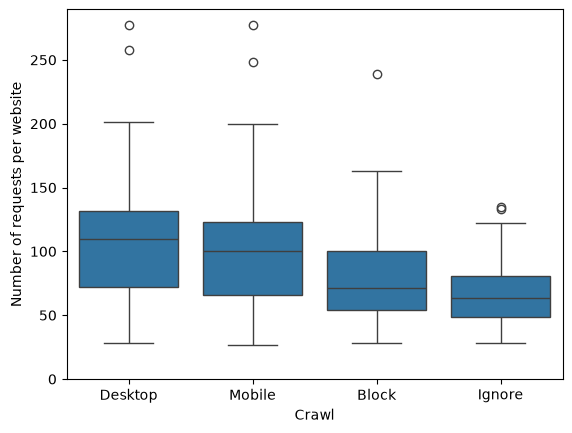

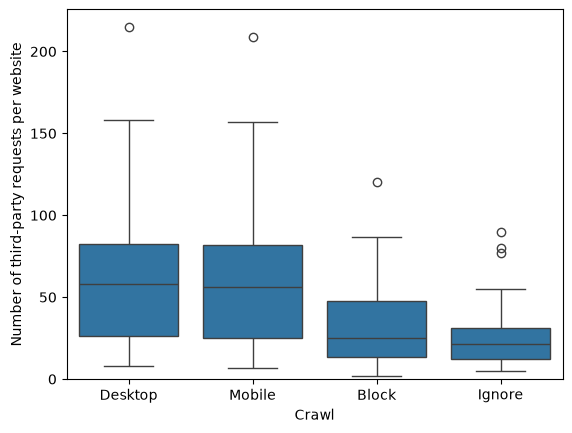

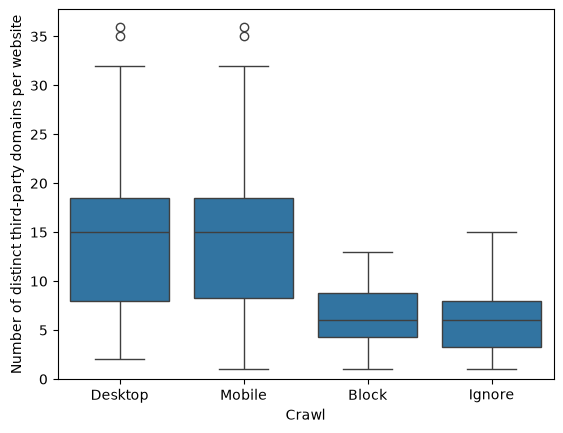

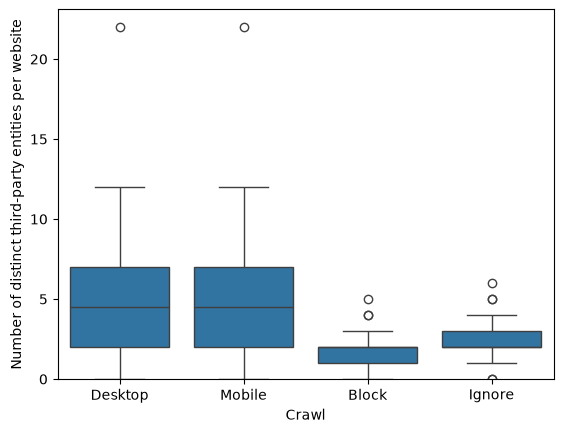

In [27]:
def plot_metric_boxplot(metric, figure_name):
    """Box plot of one metric per website, with the crawl on the X axis."""
    sns.boxplot(data=site_metrics, x="crawl", y=metric, order=CRAWLS)
    plt.xlabel("Crawl")
    plt.ylabel(metric + " per website")
    plt.ylim(bottom=0)
    plt.savefig(f"figures/{figure_name}.png", dpi=200, bbox_inches="tight")
    plt.show()

plot_metric_boxplot("Number of requests", "Q1a_requests")
plot_metric_boxplot("Number of third-party requests", "Q1b_third_party_requests")
plot_metric_boxplot("Number of distinct third-party domains", "Q1c_third_party_domains")
plot_metric_boxplot("Number of distinct third-party entities", "Q1d_third_party_entities")

Q2: min, median and max of each Q1 metric, per crawl

In [30]:

summary_table = (
    site_metrics
    .groupby("crawl")[METRICS] # split the 120 rows into the 4 crawls (30 websites each)
    .agg(["min", "median", "max"]) # for every metric: min, median and max over the 30 websites
    .T  # transpose: metrics become rows, crawls become columns
)

summary_table = summary_table[CRAWLS] # put the columns in the order Desktop, Mobile, Block, Ignore
summary_table.to_csv("figures/Q2_summary_table.csv") # save the table for the report

summary_table.style.format("{:g}") # show the table without unnecessary decimals (6 instead of 6.0)